In [1]:
# 1. What is the problem / business objective?

# A Telco company wants to hire our consulting service to try to reduce their churn rate. However,
# they do not only require our expertise to identify the clients whose risk of churn is higher, they
# want us to help them launch a more effective retention campaign. The ultimate goal is to help the
# company increase their revenue.

# We need to understand that losing a customer is very costly. It normally takes a few new customers
# to equal the cost of losing a customer because many of them will join due to some special offers
# (the income margin from new customers is lower).

# Therefore, we will need our classification model to be very sensible with false negative cases.
# All those cases imply a big cost to the company. Later, when we apply our retention campaign to
# the cases that are predicted as positive, we will need to predict those for which a retention
# campaign can have a positive impact and make them stay. We will have a fix amount of budget to
# spend on retention. The impact of our retention campaign will be evaluated doing A/B testing.

# Our job will be successful if we help the company earn more money. In this case, it seems that
# this implies that we will reduce the churn rate. Although, it does not have to be necessarily the
# case as the company might already be using a very ineffective churn rate, which keeps many customers
# in the company but at a very high cost (e.g. giving a discount for every customer that calls to
# complain and threats to leave to another company). We need to be mindful on the fact that Telco
# service does not generate as much fidelity as electric market, for instance. The competence is very
# strong as well.


In [2]:
# 2. What data is available?

# The company is giving us access to their database. Inside we can find all the relevant data about customers:
# some personal data, the phone and internet services they signed up for, some other additional services,
# contract type, time within the company, monthly charges, total charges, etc. Furthermore, we have the
# information of if the customer churned during the last month or not. This is essential to train a
# supervised model.

# Here is a more detail description:

# Each row represents a customer, each column contains customer’s attributes described
# on the column Metadata.

# The data set includes information about:

# Customers who left within the last month – the column is called Churn
# Services that each customer has signed up for – phone, multiple lines, internet, online security, online backup, device protection, tech support, and streaming TV and movies
# Customer account information – how long they’ve been a customer, contract, payment method, paperless billing, monthly charges, and total charges
# Demographic info about customers – gender, age range, and if they have partners and dependents

# Variables:
# "name":"gender","description":"Whether the customer is a male or a female"
# "name":"SeniorCitizen","description":"Whether the customer is a senior citizen or not (1, 0)"
# "name":"Partner","description":"Whether the customer has a partner or not (Yes, No)"
# "name":"Dependents","description":"Whether the customer has dependents or not (Yes, No)"
# "name":"tenure","description":"Number of months the customer has stayed with the company"
# "name":"PhoneService","description":"Whether the customer has a phone service or not (Yes, No)
# "name":"MultipleLines","description":"Whether the customer has multiple lines or not (Yes, No, No phone service)"
# "name":"InternetService","description":"Customer\u2019s internet service provider (DSL, Fiber optic, No)"
# "name":"OnlineSecurity","description":"Whether the customer has online security or not (Yes, No, No internet service)"
# "name":"OnlineBackup","description":"Whether the customer has online backup or not (Yes, No, No internet service)
# "name":"DeviceProtection","description":"Whether the customer has device protection or not (Yes, No, No internet service)"
# "name":"TechSupport","description":"Whether the customer has tech support or not (Yes, No, No internet service)"
# "name":"StreamingTV","description":"Whether the customer has streaming TV or not (Yes, No, No internet service) "
# "name":"StreamingMovies","description":"Whether the customer has streaming movies or not (Yes, No, No internet service)"
# "name":"Contract","description":"The contract term of the customer (Month-to-month, One year, Two year)"
# "name":"PaperlessBilling","description":"Whether the customer has paperless billing or not (Yes, No)"
# "name":"PaymentMethod","description":"The customer\u2019s payment method (Electronic check, Mailed check, Bank transfer (automatic), Credit card (automatic))"
# "name":"MonthlyCharges","description":"The amount charged to the customer monthly"
# "name":"TotalCharges","description":"The total amount charged to the customer"
# "name":"Churn","description":"Whether the customer churned or not (Yes or No)"

# As we see in the description, each observation represents the information about a single customer. Thus,
# the unit of analysis is the customer.


In [3]:
# 3. What are the business requirements / constraints?

# Most of the relevant information has been stated in the business objective section. However,
# there is one additional aspect we need to be specially careful, which is the time horizon.
# When we train the model in future iterations, we need to order the data temporarily. Why?
# Because we can not actual customers data to predict customers that churned a while ago. That
# would be temporal data leakage. Therefore, we would use for training the old data and keep the
# most recent for testing.

In [4]:
# 4. Understand the variables

# We take a first close look to the data that is available. We will look into variables type,
# attempt to make type conversions if allowed and analyze every variable's values or categories
# to see if they match with their definition.

# Import the dataset
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
pd.set_option("display.expand_frame_repr", False)

input_dataset_path = "../../data/input/telco_customer_churn.csv"
original_df = pd.read_csv(input_dataset_path)

df = original_df.copy()

# We print the columns and watch the first observations
print(df.columns)
print(df.head())

# Let us look at the types and convert to the expected ones
print(df.dtypes)
# These are the types they have:
# customerID              str
# gender                  str
# SeniorCitizen         int64
# Partner                 str
# Dependents              str
# tenure                int64
# PhoneService            str
# MultipleLines           str
# InternetService         str
# OnlineSecurity          str
# OnlineBackup            str
# DeviceProtection        str
# TechSupport             str
# StreamingTV             str
# StreamingMovies         str
# Contract                str
# PaperlessBilling        str
# PaymentMethod           str
# MonthlyCharges      float64
# TotalCharges            str
# Churn                   str

# These are the types they should have:
types_mapping_transformation = {
    "customerID": "str",
    "gender": "category",
    "SeniorCitizen": "category",
    "Partner": "category",
    "Dependents": "category",
    "tenure": "int64",
    "PhoneService": "category",
    "MultipleLines": "category",
    "InternetService": "category",
    "OnlineSecurity": "category",
    "OnlineBackup": "category",
    "DeviceProtection" : "category",
    "TechSupport": "category",
    "StreamingTV": "category",
    "StreamingMovies": "category",
    "Contract": "category",
    "PaperlessBilling": "category",
    "PaymentMethod": "category",
    "MonthlyCharges": "float64",
    "TotalCharges": "float64",
    "Churn": "category",
}

# Before changing types, we need to transform empty spaces cell into nan values in
# TotalCharges
df["TotalCharges"] = df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True)
df = df.astype(types_mapping_transformation)

# What are the possible values of every variable?
for col in df.columns:
    print(df[col].value_counts(normalize=True))

# After analyzing the outputs, we confirm that the values match the definitions.

# We see that customerID is the identifier column of customers.

# Churn column is the target variable


Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'], dtype='str')
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService     MultipleLines InternetService OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling              PaymentMethod  MonthlyCharges TotalCharges Churn
0  7590-VHVEG  Female              0     Yes         No       1           No  No phone service             DSL             No          Yes               No          No          No              No  Month-to-month              Yes           Electronic check           29.85        29.85    No
1  5575-GNVDE    Male              0      No         No      34          Y

In [5]:
# 5. Understand the target

print(df["Churn"].value_counts(normalize=True))

# Churn
# No     0.73463
# Yes    0.26537

# We see that there is some class imbalance, although it does not seem dramatic. For now,
# it does not look necessary to apply any sampling method.

# We also see that the definition is consistent with the business question, where 27% of
# customers churn. This causes a big economic loss of the company.

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


In [6]:
# 6. Assess data quality

print(df.duplicated().any())
# There are no duplicate rows.

print(df["customerID"].duplicated().any())
# All customer IDs are unique.

# We see if there are any missing values
print(df.isna().sum())

# customerID           0
# gender               0
# SeniorCitizen        0
# Partner              0
# Dependents           0
# tenure               0
# PhoneService         0
# MultipleLines        0
# InternetService      0
# OnlineSecurity       0
# OnlineBackup         0
# DeviceProtection     0
# TechSupport          0
# StreamingTV          0
# StreamingMovies      0
# Contract             0
# PaperlessBilling     0
# PaymentMethod        0
# MonthlyCharges       0
# TotalCharges        11
# Churn                0

# The only missings are found in TotalCharges. This is a very positive sign.
mask = df["TotalCharges"].isna()
print(df[mask])

# We see that all cases have one pattern: tenure = 0. This means that they are new joiners.
# Thus, nothing has been charged to them yet. So we are safe by converting their TotalCharges
# value equal 0. We now analyze the relationship between totalCharges and tenure
# and MonthlyCharges.

# Check if monthly charges multiplied by tenure equals totalcharges
mask = df["tenure"] * df["MonthlyCharges"] == df["TotalCharges"]
totalCharges_bigger_mask = df["tenure"] * df["MonthlyCharges"] < df["TotalCharges"]
totalCharges_smaller_mask = df["tenure"] * df["MonthlyCharges"] > df["TotalCharges"]

# We find out that sometimes totalCharges = tenure * MonthlyCharges but most of the
# times is not equal. When the equality is not met, half of the times totalCharges is bigger and half of
# times is smaller. Thus, the hypothesis of extra costs included in totalCharges that are not contemplated
# in MonthlyCharges loses power. The biggest hypothesis now is that MonthlyCharges changes through time.

# Convert nan values to 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# * Invalid values?
# We are going to search for non logical combinations.
phone_nonlogical_combination_mask = (df["PhoneService"] == "No") & (df["MultipleLines"] != "No phone service")
print(len(df[phone_nonlogical_combination_mask]))

internet_nonlogical_combination_mask = (df["InternetService"] == "No") & ((df["OnlineSecurity"] != "No internet service") | (df["OnlineBackup"] != "No internet service") | (df["DeviceProtection"] != "No internet service") | (df["TechSupport"] != "No internet service") | (df["StreamingTV"] != "No internet service") | (df["StreamingMovies"] != "No internet service"))
print(len(df[internet_nonlogical_combination_mask]))

# In section 4, we visualize the categories of every variable and we did not find any inconsitency.

# * Inconsistent categories?
# In section 4, we visualize the categories of every variable and we did not find any inconsitency.

# * Unexpected distributions?
columns = list(df.columns)

categorical_columns = df.select_dtypes(include=["category", "object", "string"]).columns.to_list()
categorical_columns.remove("customerID")
numerical_columns = [column for column in df.columns if column not in categorical_columns and column != "customerID"]

for variable in categorical_columns:
    print(df[variable].value_counts(normalize=True))

print(df.describe())

# gender
# Male      0.504756
# Female    0.495244
# Name: proportion, dtype: float64
# SeniorCitizen
# 0    0.837853
# 1    0.162147
# Name: proportion, dtype: float64
# Partner
# No     0.516967
# Yes    0.483033
# Name: proportion, dtype: float64
# Dependents
# No     0.700412
# Yes    0.299588
# Name: proportion, dtype: float64
# PhoneService
# Yes    0.903166
# No     0.096834
# Name: proportion, dtype: float64
# MultipleLines
# No                  0.481329
# Yes                 0.421837
# No phone service    0.096834
# Name: proportion, dtype: float64
# InternetService
# Fiber optic    0.439585
# DSL            0.343746
# No             0.216669
# Name: proportion, dtype: float64
# OnlineSecurity
# No                     0.496663
# Yes                    0.286668
# No internet service    0.216669
# Name: proportion, dtype: float64
# OnlineBackup
# No                     0.438450
# Yes                    0.344881
# No internet service    0.216669
# Name: proportion, dtype: float64
# DeviceProtection
# No                     0.439443
# Yes                    0.343888
# No internet service    0.216669
# Name: proportion, dtype: float64
# TechSupport
# No                     0.493114
# Yes                    0.290217
# No internet service    0.216669
# Name: proportion, dtype: float64
# StreamingTV
# No                     0.398978
# Yes                    0.384353
# No internet service    0.216669
# Name: proportion, dtype: float64
# StreamingMovies
# No                     0.395428
# Yes                    0.387903
# No internet service    0.216669
# Name: proportion, dtype: float64
# Contract
# Month-to-month    0.550192
# Two year          0.240664
# One year          0.209144
# Name: proportion, dtype: float64
# PaperlessBilling
# Yes    0.592219
# No     0.407781
# Name: proportion, dtype: float64
# PaymentMethod
# Electronic check             0.335794
# Mailed check                 0.228880
# Bank transfer (automatic)    0.219225
# Credit card (automatic)      0.216101
# Name: proportion, dtype: float64
# Churn
# No     0.73463
# Yes    0.26537
# Name: proportion, dtype: float64
#             tenure  MonthlyCharges  TotalCharges
# count  7043.000000     7043.000000   7043.000000
# mean     32.371149       64.761692   2279.734304
# std      24.559481       30.090047   2266.794470
# min       0.000000       18.250000      0.000000
# 25%       9.000000       35.500000    398.550000
# 50%      29.000000       70.350000   1394.550000
# 75%      55.000000       89.850000   3786.600000
# max      72.000000      118.750000   8684.800000

# The univariate distributions show very healthy and correct behaviours.

# * Outliers?
print(numerical_columns)
for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()

    print(f"{col}: {n_outliers} outliers")

# We do not have values outside the lower and upper bound. This is a positive sign. It does not
# mean that there are no outliers but data is concentrated in a bounded range.

False
False
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64
      customerID  gender SeniorCitizen Partner Dependents  tenure PhoneService     MultipleLines InternetService       OnlineSecurity         OnlineBackup     DeviceProtection          TechSupport          StreamingTV      StreamingMovies  Contract PaperlessBilling              PaymentMethod  MonthlyCharges  TotalCharges Churn
488   4472-LVYGI  Female             0     Yes        Yes       0           No  No phone service             DSL                  Yes                   No         

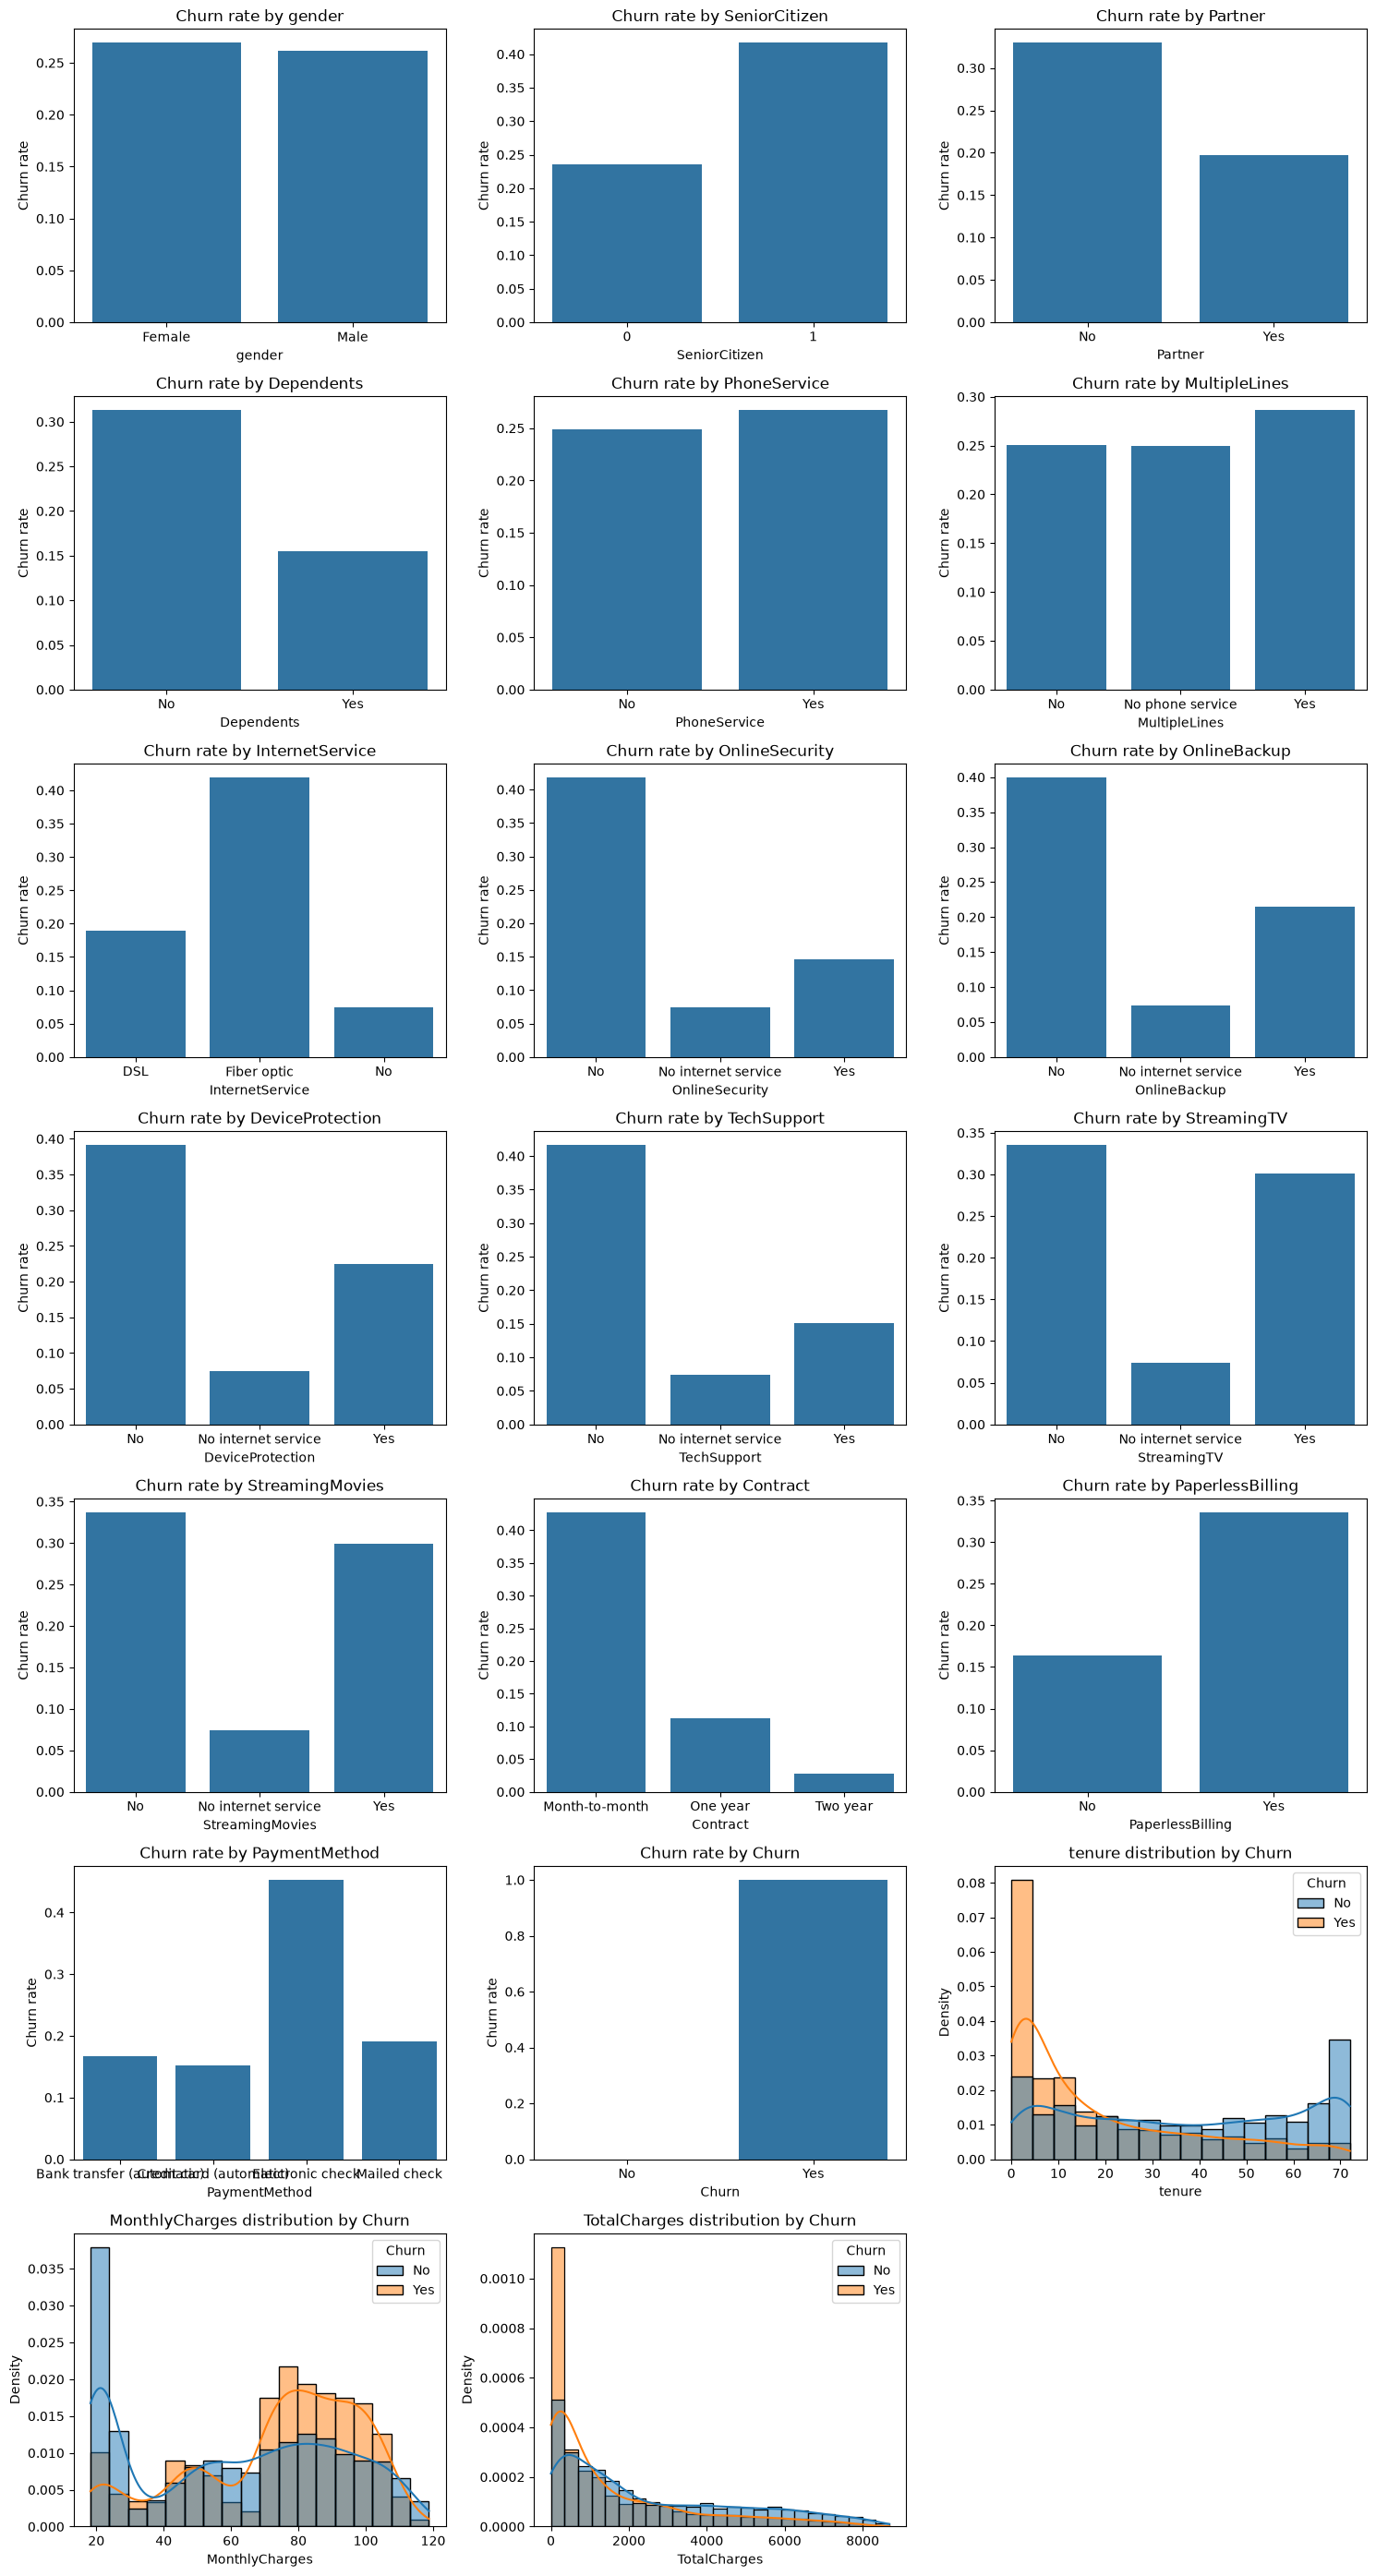

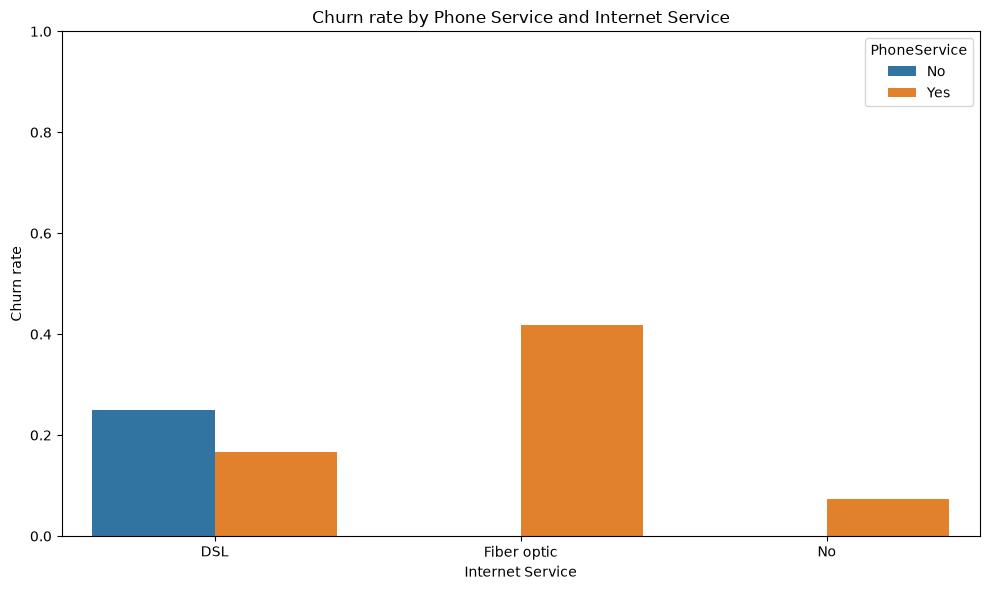

                  tenure  MonthlyCharges  TotalCharges  Churn_binary
tenure          1.000000        0.247900      0.826178     -0.352229
MonthlyCharges  0.247900        1.000000      0.651174      0.193356
TotalCharges    0.826178        0.651174      1.000000     -0.198324
Churn_binary   -0.352229        0.193356     -0.198324      1.000000


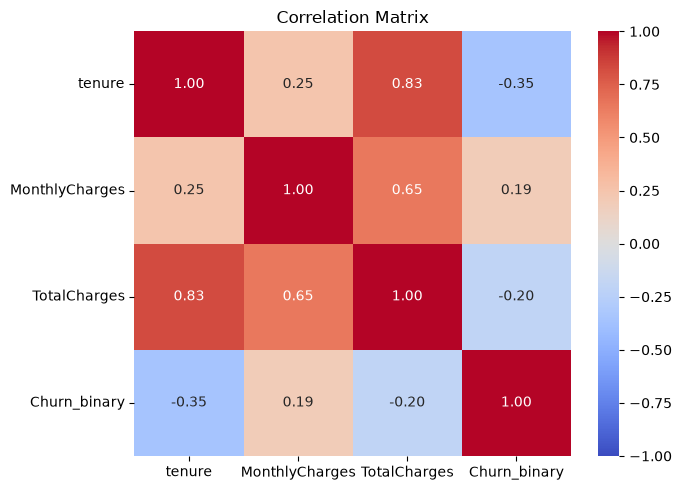

Pearson correlation:
                  tenure  MonthlyCharges  TotalCharges  Churn_binary
tenure          1.000000        0.247900      0.826178     -0.352229
MonthlyCharges  0.247900        1.000000      0.651174      0.193356
TotalCharges    0.826178        0.651174      1.000000     -0.198324
Churn_binary   -0.352229        0.193356     -0.198324      1.000000

Spearman correlation:
                  tenure  MonthlyCharges  TotalCharges  Churn_binary
tenure          1.000000        0.276417      0.889696     -0.367062
MonthlyCharges  0.276417        1.000000      0.638028      0.184743
TotalCharges    0.889696        0.638028      1.000000     -0.229955
Churn_binary   -0.367062        0.184743     -0.229955      1.000000


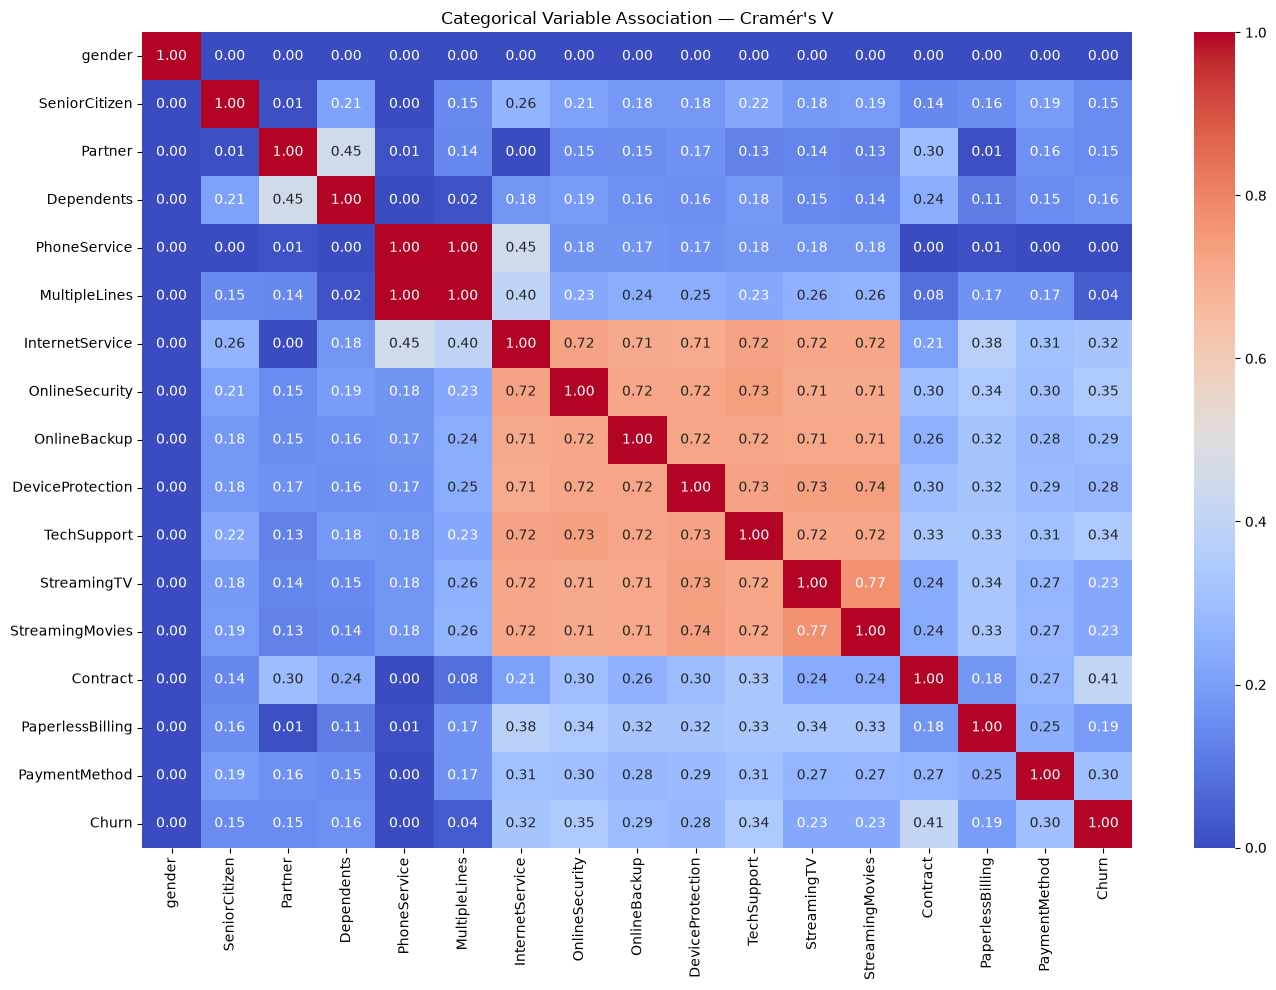

In [7]:
# 7. How does the target behave across the different characteristics of the customers?
import seaborn as sns
import matplotlib.pyplot as plt
import math

all_features = categorical_columns + numerical_columns

n_cols = 3
n_rows = math.ceil(len(all_features) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(15, 4 * n_rows)
)

axes = axes.flatten()

for i, variable in enumerate(all_features):

    if variable in categorical_columns:

        # Churn rate for each category
        churn_rate = (
            df.groupby(variable, observed=True)["Churn"]
            .apply(lambda x: (x == "Yes").mean())
            .reset_index(name="ChurnRate")
        )

        sns.barplot(
            data=churn_rate,
            x=variable,
            y="ChurnRate",
            ax=axes[i]
        )

        axes[i].set_title(f"Churn rate by {variable}")
        axes[i].set_ylabel("Churn rate")

    else:
        # Numeric distribution split by target
        sns.histplot(
            data=df,
            x=variable,
            hue="Churn",
            kde=True,
            stat="density",
            common_norm=False,
            ax=axes[i]
        )

        axes[i].set_title(f"{variable} distribution by Churn")
        axes[i].set_ylabel("Density")

# Remove unused axes
for i in range(len(all_features), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

# Let us divide our analysis in 2 parts. First, the variables that seem to have a association with the target.
# This happens when we see a clear different behaviour of the target when moving through different
# categories or ranges (numerical). And then we will talk about the correlations we see between predictors.

# Female and male are very even. So it does not seem to have a powerful association with the target. SeniorCitizen has a relevant
# difference (almost twice as high the churn rate in citizens) but there are way more citizens than
# non citizens. So that also influences. The churn rate is notibly higher in people with no partner, this
# could be because when people commit they have a more stable life. The same conclusions for dependents.
# In fact there seems to be a strong correlation between the 2 variables. Phone service show very uniform
# distribution (also if they have multiple lines or not), so it does not seem to have a big association with the target.
# People with no internet service tend to churn more and people that did not hire many internet accesories
# (security and back up, for instance) tend to churn more. We kind of start drawing the following conclusion:
# the more services you have with the telco, the less likely you are to churn, which makes sense. People
# with fiber optic churn more. There seems to be a big correlation between the internet accesories variables.
# It is surprising that there is a high churn rate in people that hire streaming TV or streaming movies
# (both seem to have a high correlation). Month to month contract have a very high churn rate (it makes sense),
# while two year contract have an almost zero rate. One year contracts have a 10% rate. People that pay
# with electronic check have a super high churn rate (40%). Tenure and totalCharges seem to have a high
# correlation and a high association with the target. From month 20 and total charges around 1000 the density of
# churn is lower than the no churn. In monthly charges, we clearly see that from cost of 70 the churn increases
# considerably.

# We are missing to see how churn behaves when we combined phone service and internet service categories.
# This can be very insightful as well.

churn_combination = (
    df.groupby(["PhoneService", "InternetService"], observed=True)["Churn"]
      .apply(lambda x: (x == "Yes").mean())
      .reset_index(name="ChurnRate")
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=churn_combination,
    x="InternetService",
    y="ChurnRate",
    hue="PhoneService"
)

plt.title("Churn rate by Phone Service and Internet Service")
plt.ylabel("Churn rate")
plt.xlabel("Internet Service")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# We see that there is only phone service when you hire internet service. This confirms a high correlation
# between those variables. And it also confirms that phone variables seem to have a poor association to the target.

# Now let us move to the correlation analysis.

# Binary representation of the target
df["Churn_binary"] = (df["Churn"] == "Yes").astype(int)

# Correlation matrix
corr_matrix = df[numerical_columns + ["Churn_binary"]].corr()

print(corr_matrix)

# Plot
plt.figure(figsize=(7, 5))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

pearson_corr = df[numerical_columns + ["Churn_binary"]].corr(
    method="pearson"
)

spearman_corr = df[numerical_columns + ["Churn_binary"]].corr(
    method="spearman"
)

print("Pearson correlation:")
print(pearson_corr)

print("\nSpearman correlation:")
print(spearman_corr)

def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)

    observed = confusion_matrix.values

    # Chi-square statistic
    chi2 = (
        observed - np.outer(observed.sum(axis=1), observed.sum(axis=0))
        / observed.sum()
    ) ** 2

    chi2 = (
        chi2
        / (
            np.outer(observed.sum(axis=1), observed.sum(axis=0))
            / observed.sum()
        )
    ).sum()

    n = observed.sum()
    phi2 = chi2 / n

    r, k = observed.shape

    phi2corr = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)

    return np.sqrt(
        phi2corr / min(kcorr - 1, rcorr - 1)
    )

cramers_matrix = pd.DataFrame(
    index=categorical_columns,
    columns=categorical_columns,
    dtype=float
)

for col1 in categorical_columns:
    for col2 in categorical_columns:
        cramers_matrix.loc[col1, col2] = cramers_v(
            df[col1],
            df[col2]
        )

plt.figure(figsize=(14, 10))

sns.heatmap(
    cramers_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=0,
    vmax=1
)

plt.title("Categorical Variable Association — Cramér's V")
plt.tight_layout()
plt.show()

# All results confirm our previous comments.

In [17]:
# 8. Train different models and select the ones that give better results

# Create the pipeline to preprocess and train a model
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_val_predict, train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.metrics import confusion_matrix, make_scorer, recall_score

# We get rid of customerID and the generated churn binary
for var in ["customerID", "Churn_binary"]:
    if var in list(df.columns):
        df = df.drop(columns=["customerID", "Churn_binary"])

y = df["Churn"]
X = df.drop(columns=["Churn"])

# Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Remove churn from categorical columns
categorical_columns = [var for var in categorical_columns if var !="Churn"]

preprocessor = ColumnTransformer(
    transformers=[
        ("numerical_encoding", MinMaxScaler(), numerical_columns),
        ("categorical_encoding", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

def train_model_and_predict(model, param_grid, metric=recall_score):
    metric_yes = make_scorer(
        metric,
        pos_label="Yes"
    )

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring=metric_yes,
        cv=5,
        n_jobs=-1,
        refit=True,
        error_score="raise",
    )

    # * Fit using only the training data
    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_

    # Calculate the thresholds that give better results
    y_train_proba = cross_val_predict(
        best_model,
        X_train,
        y_train,
        cv=5,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    thresholds = np.arange(0.1, 0.91, 0.01)

    threshold_results = []

    for threshold in thresholds:
        y_train_pred = np.where(
            y_train_proba >= threshold,
            "Yes",
            "No"
        )

        recall = recall_score(
            y_train,
            y_train_pred,
            pos_label="Yes"
        )

        threshold_results.append({
            "threshold": threshold,
            "recall": recall
        })

    threshold_results = pd.DataFrame(threshold_results)

    best_threshold = threshold_results.loc[
        threshold_results["recall"].idxmax(),
        "threshold"
    ]

    print("Best threshold:", best_threshold)

    y_test_proba = best_model.predict_proba(X_test)[:, 1]

    y_pred = np.where(
        y_test_proba >= best_threshold,
        "Yes",
        "No"
    )

    print("\nConfusion matrix:")
    print(confusion_matrix(y_test, y_pred))

    return recall_score(
        y_test,
        y_pred,
        pos_label="Yes"
    )


In [18]:
# Train and eval recall on logistic regression
from sklearn.linear_model import LogisticRegression


logistic_param_grid = {
    "model__C": [
        0.001,
        0.01,
        0.1,
        1,
        10,
        100,
        1000,
        10000,
    ],
    "model__solver": [
        "liblinear",
        "lbfgs",
    ],
    "model__max_iter": [
        1000
    ],
}

logistic_results = train_model_and_predict(
    model=LogisticRegression(),
    param_grid=logistic_param_grid
)

print(logistic_results)

Best threshold: 0.1

Confusion matrix:
[[656 638]
 [ 26 441]]
0.9443254817987152


In [19]:
from sklearn.tree import DecisionTreeClassifier

tree_param_grid = {
    "model__max_depth": [
        2,
        3,
        4,
        5,
        6,
        8,
        10,
        None,
    ],
    "model__min_samples_split": [
        2,
        5,
        10,
        20,
    ],
    "model__min_samples_leaf": [
        1,
        2,
        5,
        10,
    ],
    "model__criterion": [
        "gini",
        "entropy",
    ],
}

decision_tree_results = train_model_and_predict(
    model=DecisionTreeClassifier(
        random_state=42
    ),
    param_grid=tree_param_grid
)

print(decision_tree_results)

Best threshold: 0.1

Confusion matrix:
[[579 715]
 [ 23 444]]
0.9507494646680942


In [20]:
from sklearn.ensemble import RandomForestClassifier


random_forest_param_grid = {
    "model__n_estimators": [200],
    "model__max_depth": [5, 10, None],
    "model__min_samples_leaf": [1, 5, 10],
    "model__max_features": ["sqrt", None],
}


random_forest_results = train_model_and_predict(
    model=RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    param_grid=random_forest_param_grid
)

print(random_forest_results)

Best threshold: 0.1

Confusion matrix:
[[600 694]
 [ 25 442]]
0.9464668094218416


In [ ]:
# print("Cost:", business_cost(y_test, y_pred))

# print("Accuracy:", accuracy_score(y_test, y_pred))
# print("Precision:", precision_score(y_test, y_pred, pos_label="Yes"))
# print("Recall:", recall_score(y_test, y_pred, pos_label="Yes"))
# print("F1:", f1_score(y_test, y_pred, pos_label="Yes"))

# print("\nConfusion matrix:")
# print(confusion_matrix(y_test, y_pred))

# print("\nClassification report:")
# print(classification_report(y_test, y_pred))

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'], dtype='str')
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService     MultipleLines InternetService OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling              PaymentMethod  MonthlyCharges TotalCharges Churn
0  7590-VHVEG  Female              0     Yes         No       1           No  No phone service             DSL             No          Yes               No          No          No              No  Month-to-month              Yes           Electronic check           29.85        29.85    No
1  5575-GNVDE    Male              0      No         No      34          Y

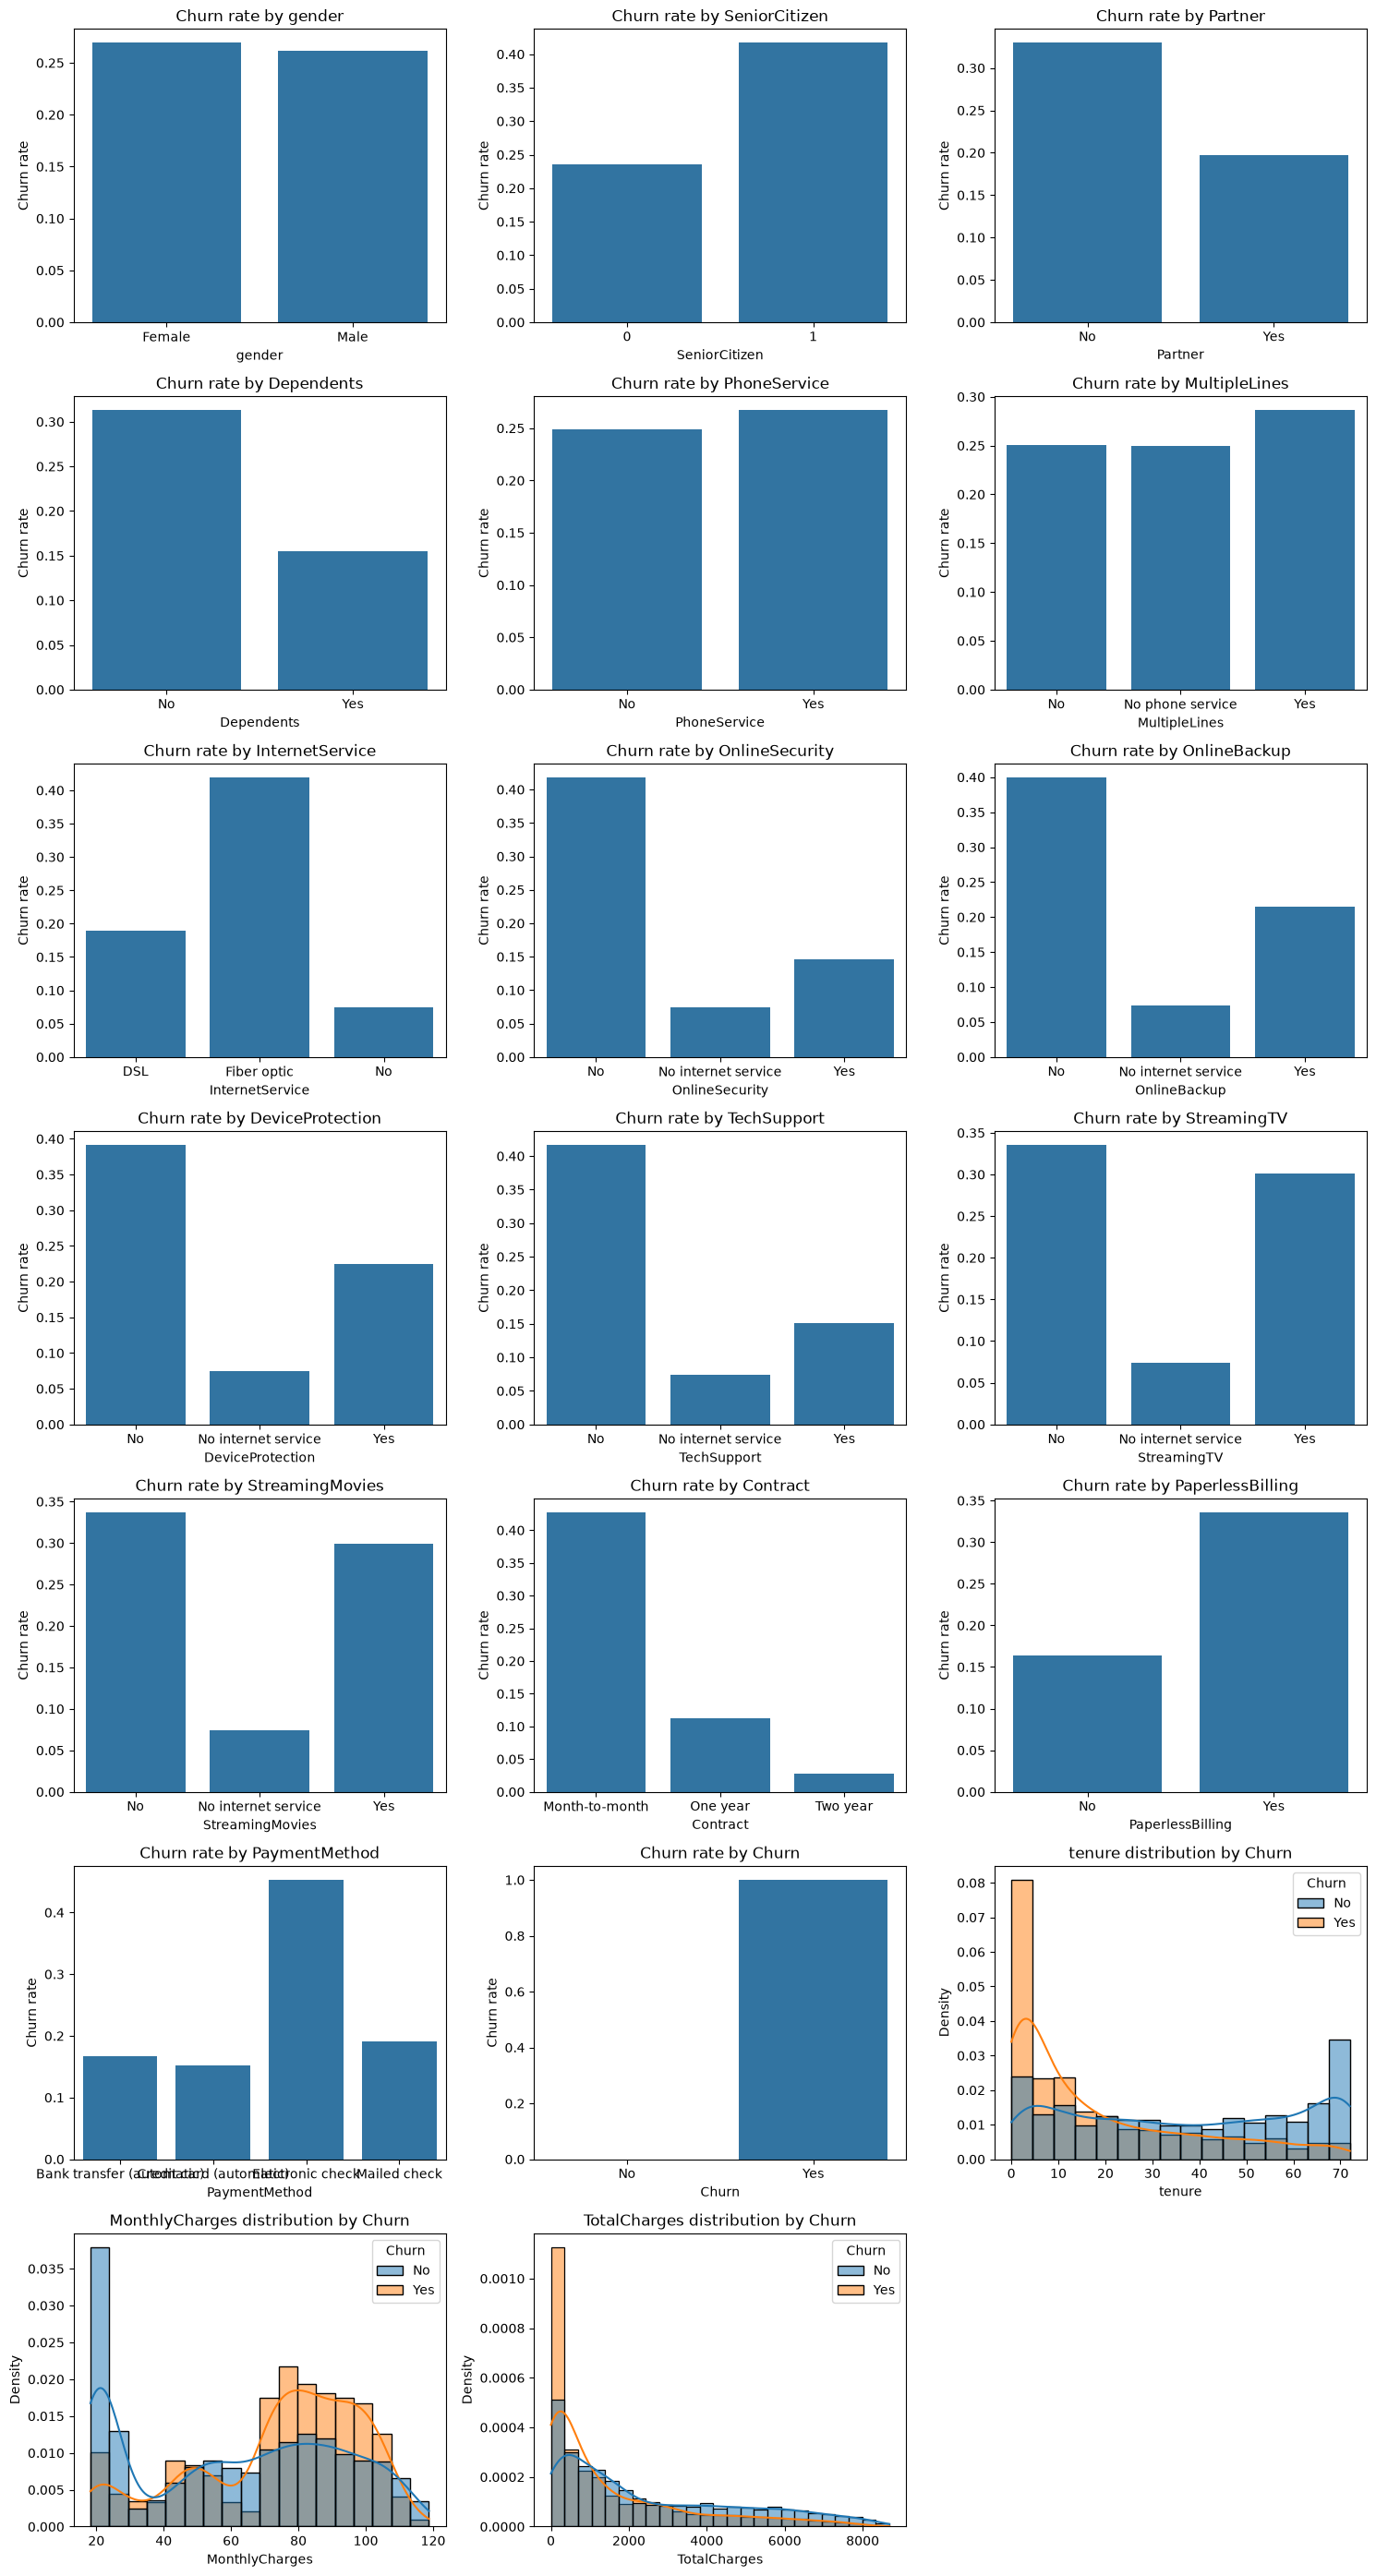

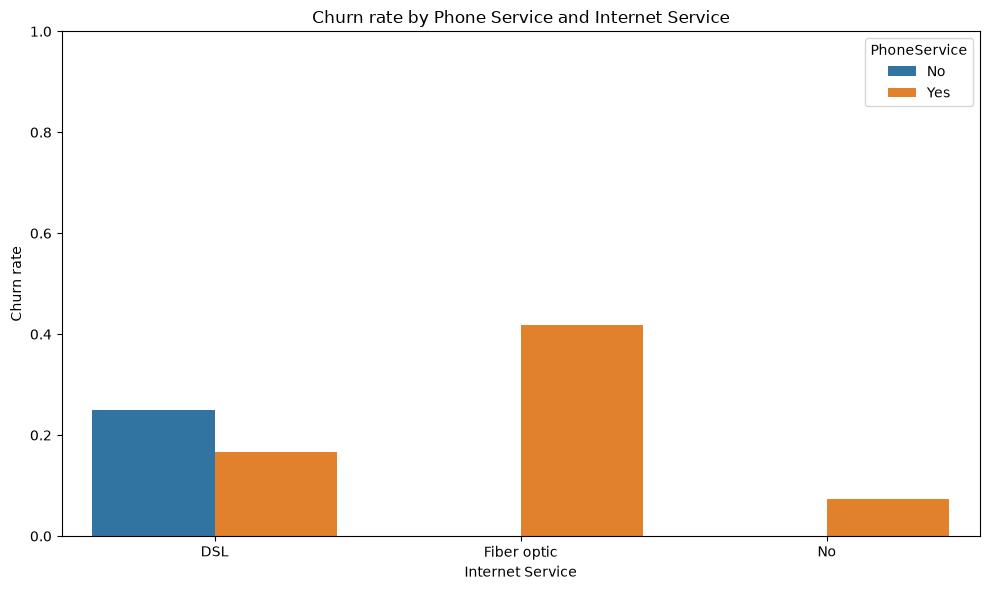

                  tenure  MonthlyCharges  TotalCharges  Churn_binary
tenure          1.000000        0.247900      0.826178     -0.352229
MonthlyCharges  0.247900        1.000000      0.651174      0.193356
TotalCharges    0.826178        0.651174      1.000000     -0.198324
Churn_binary   -0.352229        0.193356     -0.198324      1.000000


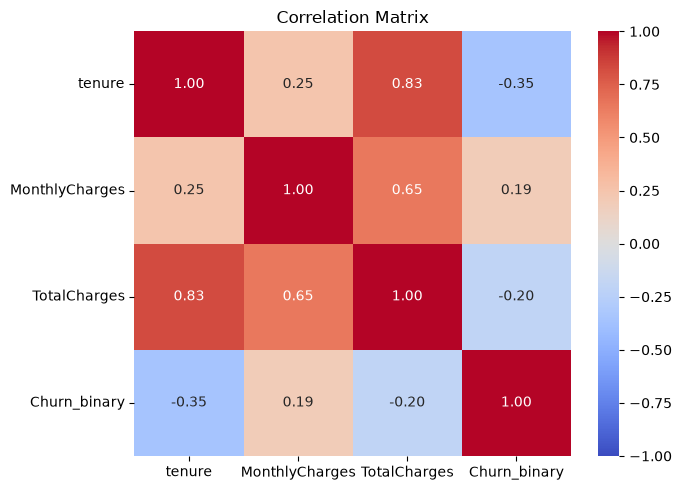

Pearson correlation:
                  tenure  MonthlyCharges  TotalCharges  Churn_binary
tenure          1.000000        0.247900      0.826178     -0.352229
MonthlyCharges  0.247900        1.000000      0.651174      0.193356
TotalCharges    0.826178        0.651174      1.000000     -0.198324
Churn_binary   -0.352229        0.193356     -0.198324      1.000000

Spearman correlation:
                  tenure  MonthlyCharges  TotalCharges  Churn_binary
tenure          1.000000        0.276417      0.889696     -0.367062
MonthlyCharges  0.276417        1.000000      0.638028      0.184743
TotalCharges    0.889696        0.638028      1.000000     -0.229955
Churn_binary   -0.367062        0.184743     -0.229955      1.000000


KeyboardInterrupt: 

In [18]:
# 1. What is the problem / business objective?

# * What are we trying to predict/estimate/optimize?
# Our Telco client is suffering a relevant churn problem. They said that we will see the dimension
# of the problem when we dive deep into their available data.

# This is expressed in the following terms:
# About Dataset
# Context
# "Predict behavior to retain customers. You can analyze all relevant customer data
# and develop focused customer retention programs." [IBM Sample Data Sets]

# * What would make the analysis successful?
# The success would come by helping the client understand the reason of the increase in churn. We have
# received no information about how much we need to reduce it, so we assume that as much as possible.
# In conclusion, we need to understand what is causing the churn and how to minimize it.


# 2. What data is available?

# * What datasets do we have?
# The client posseses one centralized dataset with all the relevant metadata as well. This will help us
# understand what information they collect from customers and their contracts and what those variables mean
# and the possible values they can take.

# * What metadata/documentation do we have?
# The metadata available contains the descriptions of the variables and information on the possible values
# they can take. Here is the documentation:
# Content
# Each row represents a customer, each column contains customer’s attributes described
# on the column Metadata.

# The data set includes information about:

# Customers who left within the last month – the column is called Churn
# Services that each customer has signed up for – phone, multiple lines, internet, online security, online backup, device protection, tech support, and streaming TV and movies
# Customer account information – how long they’ve been a customer, contract, payment method, paperless billing, monthly charges, and total charges
# Demographic info about customers – gender, age range, and if they have partners and dependents

# Variables:
# "name":"gender","description":"Whether the customer is a male or a female"
# "name":"SeniorCitizen","description":"Whether the customer is a senior citizen or not (1, 0)"
# "name":"Partner","description":"Whether the customer has a partner or not (Yes, No)"
# "name":"Dependents","description":"Whether the customer has dependents or not (Yes, No)"
# "name":"tenure","description":"Number of months the customer has stayed with the company"
# "name":"PhoneService","description":"Whether the customer has a phone service or not (Yes, No)
# "name":"MultipleLines","description":"Whether the customer has multiple lines or not (Yes, No, No phone service)"
# "name":"InternetService","description":"Customer\u2019s internet service provider (DSL, Fiber optic, No)"
# "name":"OnlineSecurity","description":"Whether the customer has online security or not (Yes, No, No internet service)"
# "name":"OnlineBackup","description":"Whether the customer has online backup or not (Yes, No, No internet service)
# "name":"DeviceProtection","description":"Whether the customer has device protection or not (Yes, No, No internet service)"
# "name":"TechSupport","description":"Whether the customer has tech support or not (Yes, No, No internet service)"
# "name":"StreamingTV","description":"Whether the customer has streaming TV or not (Yes, No, No internet service) "
# "name":"StreamingMovies","description":"Whether the customer has streaming movies or not (Yes, No, No internet service)"
# "name":"Contract","description":"The contract term of the customer (Month-to-month, One year, Two year)"
# "name":"PaperlessBilling","description":"Whether the customer has paperless billing or not (Yes, No)"
# "name":"PaymentMethod","description":"The customer\u2019s payment method (Electronic check, Mailed check, Bank transfer (automatic), Credit card (automatic))"
# "name":"MonthlyCharges","description":"The amount charged to the customer monthly"
# "name":"TotalCharges","description":"The total amount charged to the customer"
# "name":"Churn","description":"Whether the customer churned or not (Yes or No)"

# * What does each observation represent?
# Each observation represents a unique unrepeated customer. We will need to make sure that it is the case
# in fact when we go through the dataset.

# * What is the unit of analysis?
# The unit of analysis is the customer.


# 3. What are the business requirements / constraints?

# * What decisions will be made from the model?
# Our model will be used to predict which customers are more likely to churn. Therefore, it will help
# the client understand the customers characteristics, the reasons why but especially on who we need to
# offer them better conditions.

# * Are there constraints around interpretability, latency, cost, etc.?
# The client needs to prioritize interpretability. They need to understand the reasons as much as
# preventing at risk clients to churn. They are not so worried about latency as the model will be trained offline
# and inference does not need to run online either. Although, we will build a system that makes inference
# online. Inference is not slow, so we are safe here. Related to costs, they believe that with the amount of data
# provided (7000 clients) we will not run into big training costs.

# * What is the relevant time horizon?
# As clearly stated, churn column reflects if client churned during the last month or not. So this
# gives us the time horizon very clearly: one month. We want to try to reduce churn for the next month.
# When this model goes into production, it will be retrained every month with the new information of every
# client. Will it be necessary to remove the churns of previous months? so every month we will be removing
# old churns. Does that make sense?


# 4. Understand the variables

# In this section we start working with the dataset to answer the questions properly.
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
pd.set_option("display.expand_frame_repr", False)

input_dataset_path = "../../data/input/telco_customer_churn.csv"
original_df = pd.read_csv(input_dataset_path)

df = original_df.copy()

# * What does each variable mean?
print(df.columns)
print(df.head())

# This information was provided in the metadata. We just quickly review that all the variables
# are present, that the first few variables are consistent with the definitions. Everything
# seems fine until this point.

# * What type are they? What type should they have?
print(df.dtypes)
# These are the types they have:
# customerID              str
# gender                  str
# SeniorCitizen         int64
# Partner                 str
# Dependents              str
# tenure                int64
# PhoneService            str
# MultipleLines           str
# InternetService         str
# OnlineSecurity          str
# OnlineBackup            str
# DeviceProtection        str
# TechSupport             str
# StreamingTV             str
# StreamingMovies         str
# Contract                str
# PaperlessBilling        str
# PaymentMethod           str
# MonthlyCharges      float64
# TotalCharges            str
# Churn                   str

# These are the types they should have:
types_mapping_transformation = {
    "customerID": "str",
    "gender": "category",
    "SeniorCitizen": "category",
    "Partner": "category",
    "Dependents": "category",
    "tenure": "int64",
    "PhoneService": "category",
    "MultipleLines": "category",
    "InternetService": "category",
    "OnlineSecurity": "category",
    "OnlineBackup": "category",
    "DeviceProtection" : "category",
    "TechSupport": "category",
    "StreamingTV": "category",
    "StreamingMovies": "category",
    "Contract": "category",
    "PaperlessBilling": "category",
    "PaymentMethod": "category",
    "MonthlyCharges": "float64",
    "TotalCharges": "float64",
    "Churn": "category",
}

# Before changing types, we need to transform empty spaces cell into nan values in
# TotalCharges
df["TotalCharges"] = df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True)
df = df.astype(types_mapping_transformation)

# What are its possible values?
for variable in df.columns:
    print(variable)
    print(df[variable].unique())

# * Do the actual values match the definition?
# The values match the definitions.

# * Which variable is the target?
# Churn is the target variable.

# * Which variables are identifiers?
# CustomerID is the identifier column.


# 5. Understand the target

# * What exactly constitutes the positive/negative class?
# Positive means having churn during the last month. Positive cases are expressed with the value 1.
# On the contrary, negative cases with the value 0.

# * How frequent is it?
df["Churn"].value_counts(normalize=True)
# Churn
# No     0.73463
# Yes    0.26537

# * Is there class imbalance?
# There is a bit of imbalance but not critical. I do not think that it is necessary to apply a sampling
# technique. But we will evaluate this later.

# * Is the target definition consistent with the business question?
# It is consistent and indeed it reveals a lot of information. It says that 26% of our customers
# churned within last month. This is a big number that needs to be minimize.


# 6. Assess data quality

# * Duplicate rows?
print(df.duplicated().any())
# There are no duplicate rows.

# * Duplicate IDs?
# Now we want to make sure there is no duplicated ID.
print(df["customerID"].duplicated().any())

# There are none. This confirms that our unit of analysis is well constructed as a customer
# only appears once. Its information is concentrated in one row.

# * Missing values?
# We evaluate if there are missing values.
print(df.isna().sum())

# customerID           0
# gender               0
# SeniorCitizen        0
# Partner              0
# Dependents           0
# tenure               0
# PhoneService         0
# MultipleLines        0
# InternetService      0
# OnlineSecurity       0
# OnlineBackup         0
# DeviceProtection     0
# TechSupport          0
# StreamingTV          0
# StreamingMovies      0
# Contract             0
# PaperlessBilling     0
# PaymentMethod        0
# MonthlyCharges       0
# TotalCharges        11
# Churn                0

# The only missings are found in TotalCharges. This is a very positive sign.
mask = df["TotalCharges"].isna()
print(df[mask])

# We see that all cases have one pattern: tenure = 0. This means that they are new joiners.
# Thus, nothing has been charged to them yet. So we are safe by converting their TotalCharges
# value equal 0. We now analyze the relationship between totalCharges and tenure
# and MonthlyCharges. We find out that sometimes totalCharges = tenure * MonthlyCharges but most of the
# times is not equal. When the equality is not met, half of the times totalCharges is bigger and half of
# times is smaller. Thus, the hypothesis of extra costs included in totalCharges that are not contemplated
# in MonthlyCharges loses power. The biggest hypothesis now is that MonthlyCharges changes through time.

# Check if monthly charges multiplied by tenure equals totalcharges
mask = df["tenure"] * df["MonthlyCharges"] == df["TotalCharges"]
totalCharges_bigger_mask = df["tenure"] * df["MonthlyCharges"] < df["TotalCharges"]
totalCharges_smaller_mask = df["tenure"] * df["MonthlyCharges"] > df["TotalCharges"]
print(len(df[mask]))
print(len(df[totalCharges_bigger_mask]))
print(len(df[totalCharges_smaller_mask]))
print(np.mean(np.abs(df["tenure"] * df["MonthlyCharges"] - df["TotalCharges"])))
print(np.mean(df["tenure"] * df["MonthlyCharges"] - df["TotalCharges"]))
print(np.mean(np.abs(df["MonthlyCharges"])))

# Convert nan values to 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# * Invalid values?
# We are going to search for non logical combinations.
phone_nonlogical_combination_mask = (df["PhoneService"] == "No") & (df["MultipleLines"] != "No phone service")
print(len(df[phone_nonlogical_combination_mask]))

internet_nonlogical_combination_mask = (df["InternetService"] == "No") & ((df["OnlineSecurity"] != "No internet service") | (df["OnlineBackup"] != "No internet service") | (df["DeviceProtection"] != "No internet service") | (df["TechSupport"] != "No internet service") | (df["StreamingTV"] != "No internet service") | (df["StreamingMovies"] != "No internet service"))
print(len(df[internet_nonlogical_combination_mask]))

# There are 0 cases in both scenarios. Therefore, we do not have non logical combinations.

# * Inconsistent categories?
# In section 4, we visualize the categories of every variable and we did not find any inconsitency.

# * Unexpected distributions?
columns = list(df.columns)

categorical_columns = [col for col in columns if df[col].dtype == "category" and col != "customerID"]
numerical_columns = [col for col in columns if col not in categorical_columns and col != "customerID"]

for variable in categorical_columns:
    print(df[variable].value_counts(normalize=True))

print(df.describe())

# gender
# Male      0.504756
# Female    0.495244
# Name: proportion, dtype: float64
# SeniorCitizen
# 0    0.837853
# 1    0.162147
# Name: proportion, dtype: float64
# Partner
# No     0.516967
# Yes    0.483033
# Name: proportion, dtype: float64
# Dependents
# No     0.700412
# Yes    0.299588
# Name: proportion, dtype: float64
# PhoneService
# Yes    0.903166
# No     0.096834
# Name: proportion, dtype: float64
# MultipleLines
# No                  0.481329
# Yes                 0.421837
# No phone service    0.096834
# Name: proportion, dtype: float64
# InternetService
# Fiber optic    0.439585
# DSL            0.343746
# No             0.216669
# Name: proportion, dtype: float64
# OnlineSecurity
# No                     0.496663
# Yes                    0.286668
# No internet service    0.216669
# Name: proportion, dtype: float64
# OnlineBackup
# No                     0.438450
# Yes                    0.344881
# No internet service    0.216669
# Name: proportion, dtype: float64
# DeviceProtection
# No                     0.439443
# Yes                    0.343888
# No internet service    0.216669
# Name: proportion, dtype: float64
# TechSupport
# No                     0.493114
# Yes                    0.290217
# No internet service    0.216669
# Name: proportion, dtype: float64
# StreamingTV
# No                     0.398978
# Yes                    0.384353
# No internet service    0.216669
# Name: proportion, dtype: float64
# StreamingMovies
# No                     0.395428
# Yes                    0.387903
# No internet service    0.216669
# Name: proportion, dtype: float64
# Contract
# Month-to-month    0.550192
# Two year          0.240664
# One year          0.209144
# Name: proportion, dtype: float64
# PaperlessBilling
# Yes    0.592219
# No     0.407781
# Name: proportion, dtype: float64
# PaymentMethod
# Electronic check             0.335794
# Mailed check                 0.228880
# Bank transfer (automatic)    0.219225
# Credit card (automatic)      0.216101
# Name: proportion, dtype: float64
# Churn
# No     0.73463
# Yes    0.26537
# Name: proportion, dtype: float64
#             tenure  MonthlyCharges  TotalCharges
# count  7043.000000     7043.000000   7043.000000
# mean     32.371149       64.761692   2279.734304
# std      24.559481       30.090047   2266.794470
# min       0.000000       18.250000      0.000000
# 25%       9.000000       35.500000    398.550000
# 50%      29.000000       70.350000   1394.550000
# 75%      55.000000       89.850000   3786.600000
# max      72.000000      118.750000   8684.800000

# The univariate distributions show very normal behaviour. The many sevices offer in internet or phone tend
# to have similar distributions. This could be a sign of high correlation between those variables.

# * Outliers?

for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()

    print(f"{col}: {n_outliers} outliers")

# We do not have values outside the lower and upper bound. This is a positive sign. It does not
# mean that there are no outliers but data is concentrated in a bounded range.


# 7. How does the target behave across the different characteristics of the customers?
import seaborn as sns
import matplotlib.pyplot as plt
import math


all_features = categorical_columns + numerical_columns

n_cols = 3
n_rows = math.ceil(len(all_features) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(15, 4 * n_rows)
)

axes = axes.flatten()

for i, variable in enumerate(all_features):

    if variable in categorical_columns:

        # Churn rate for each category
        churn_rate = (
            df.groupby(variable, observed=True)["Churn"]
            .apply(lambda x: (x == "Yes").mean())
            .reset_index(name="ChurnRate")
        )

        sns.barplot(
            data=churn_rate,
            x=variable,
            y="ChurnRate",
            ax=axes[i]
        )

        axes[i].set_title(f"Churn rate by {variable}")
        axes[i].set_ylabel("Churn rate")

    else:
        # Numeric distribution split by target
        sns.histplot(
            data=df,
            x=variable,
            hue="Churn",
            kde=True,
            stat="density",
            common_norm=False,
            ax=axes[i]
        )

        axes[i].set_title(f"{variable} distribution by Churn")
        axes[i].set_ylabel("Density")

# Remove unused axes
for i in range(len(all_features), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

# Let us divide our analysis in 2 parts. First, the variables that seem to have a high predictive power.
# This happens when we see a clear different behaviour of the target when moving through different
# categories or ranges (numerical). And then we will talk about the correlations we see between predictors.

# Female and male are very even. So it does not seem a powerful predictor. SeniorCitizen has a relevant
# difference (almost twice as high the churn rate in citizens) but there are way more citizens than
# non citizens. So that also influences. The churn rate is notibly higher in people with no partner, this
# could be because when people commit they have a more stable life. The same conclusions for dependents.
# In fact there seems to be a strong correlation between the 2 variables. Phone service show very uniform
# distribution (also if they have multiple lines or not), so it does not seem to have a big impact on the target.
# People with no internet service tend to churn more and people that did not hire many internet accesories
# (security and back up, for instance) tend to churn more. We kind of start drawing the following conclusion:
# the more services you have with the telco, the less likely you are to churn, which makes sense. People
# with fiber optic churn more. There seems to be a big correlation in the internet accesories variables.
# It is surprising that there is a high churn rate in people that hire streaming TV or streaming movies
# (both seem to have a high correlation). Month to month contract have a very high churn rate (it makes sense),
# while two year contract have an almost zero rate. One year contracts have a 10% rate. People that pay
# with electronic check have a super high churn rate (40%). Tenure and totalCharges seem to have a high
# correlation and a high predictive power. From month 20 and total charges around 1000 the density of
# churn is lower than the no churn. In monthly charges, we clearly see that from cost of 70 the churn increases
# considerably.

# We are missing to see how churn behaves when we combined phone service and internet service categories.
# This can be very insightful as well.

churn_combination = (
    df.groupby(["PhoneService", "InternetService"], observed=True)["Churn"]
      .apply(lambda x: (x == "Yes").mean())
      .reset_index(name="ChurnRate")
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=churn_combination,
    x="InternetService",
    y="ChurnRate",
    hue="PhoneService"
)

plt.title("Churn rate by Phone Service and Internet Service")
plt.ylabel("Churn rate")
plt.xlabel("Internet Service")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# We see that there is only phone service when you hire internet service. This confirms a high correlation
# between those variables. And it also confirms that phone variables seem poor predictors.

# Now let us move to the correlation analysis.

# Binary representation of the target
df["Churn_binary"] = (df["Churn"] == "Yes").astype(int)

# Correlation matrix
corr_matrix = df[numerical_columns + ["Churn_binary"]].corr()

print(corr_matrix)

# Plot
plt.figure(figsize=(7, 5))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

pearson_corr = df[numerical_columns + ["Churn_binary"]].corr(
    method="pearson"
)

spearman_corr = df[numerical_columns + ["Churn_binary"]].corr(
    method="spearman"
)

print("Pearson correlation:")
print(pearson_corr)

print("\nSpearman correlation:")
print(spearman_corr)

def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)

    observed = confusion_matrix.values

    # Chi-square statistic
    chi2 = (
        observed - np.outer(observed.sum(axis=1), observed.sum(axis=0))
        / observed.sum()
    ) ** 2

    chi2 = (
        chi2
        / (
            np.outer(observed.sum(axis=1), observed.sum(axis=0))
            / observed.sum()
        )
    ).sum()

    n = observed.sum()
    phi2 = chi2 / n

    r, k = observed.shape

    phi2corr = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)

    return np.sqrt(
        phi2corr / min(kcorr - 1, rcorr - 1)
    )

cramers_matrix = pd.DataFrame(
    index=categorical_columns,
    columns=categorical_columns,
    dtype=float
)

for col1 in categorical_columns:
    for col2 in categorical_columns:
        cramers_matrix.loc[col1, col2] = cramers_v(
            df[col1],
            df[col2]
        )

plt.figure(figsize=(14, 10))

sns.heatmap(
    cramers_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=0,
    vmax=1
)

plt.title("Categorical Variable Association — Cramér's V")
plt.tight_layout()
plt.show()

# All results confirm our previous comments.